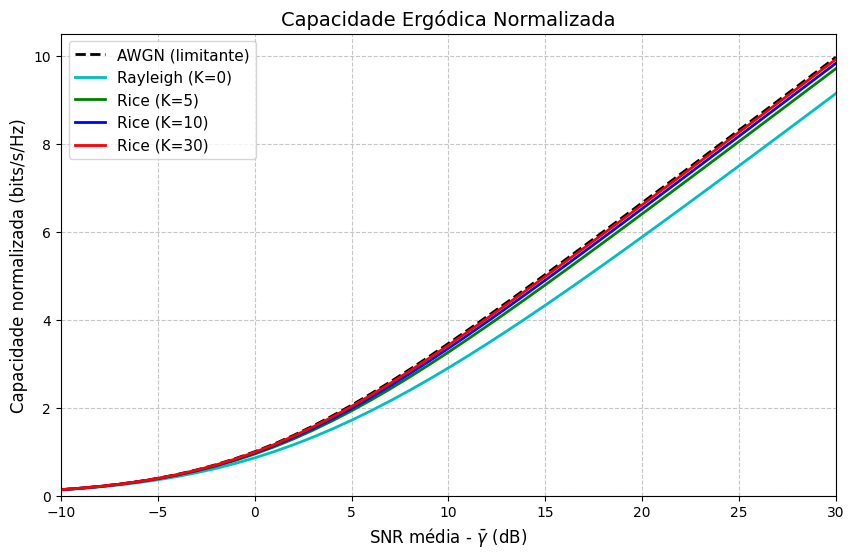

In [2]:
import matplotlib.pyplot as plt
import numpy as np

N_t = 10**6
snr_media_dB = np.arange(-10, 31, 1)
snr_media_linear = 10**(snr_media_dB / 10)
capacidade_awgn = np.log2(1 + snr_media_linear)

x_rayleigh = np.random.normal(0, np.sqrt(0.5), size=N_t)
y_rayleigh = np.random.normal(0, np.sqrt(0.5), size=N_t)
beta_ao_quadrado_rayleigh = x_rayleigh**2 + y_rayleigh**2

def gerar_beta_ao_quadrado_rice(K, size):
    mu = np.sqrt(K / (K + 1))
    sigma = np.sqrt(1 / (2 * (K + 1)))
    x = np.random.normal(mu, sigma, size)
    y = np.random.normal(0, sigma, size)
    return x**2 + y**2

beta_ao_quadrado_rice_5 = gerar_beta_ao_quadrado_rice(5, N_t)
beta_ao_quadrado_rice_10 = gerar_beta_ao_quadrado_rice(10, N_t)
beta_ao_quadrado_rice_30 = gerar_beta_ao_quadrado_rice(30, N_t)

capacidade_rayleigh = []
capacidade_rice_5 = []
capacidade_rice_10 = []
capacidade_rice_30 = []

for gamma_bar in snr_media_linear:
    capacidade_rayleigh.append(np.mean(np.log2(1 + gamma_bar * beta_ao_quadrado_rayleigh)))
    capacidade_rice_5.append(np.mean(np.log2(1 + gamma_bar * beta_ao_quadrado_rice_5)))
    capacidade_rice_10.append(np.mean(np.log2(1 + gamma_bar * beta_ao_quadrado_rice_10)))
    capacidade_rice_30.append(np.mean(np.log2(1 + gamma_bar * beta_ao_quadrado_rice_30)))

plt.figure(figsize=(10, 6))
plt.plot(snr_media_dB, capacidade_awgn, 'k--', linewidth=2, label='AWGN (limitante)')
plt.plot(snr_media_dB, capacidade_rayleigh, 'c-', linewidth=2, label='Rayleigh (K=0)')
plt.plot(snr_media_dB, capacidade_rice_5, 'g-', linewidth=2, label='Rice (K=5)')
plt.plot(snr_media_dB, capacidade_rice_10, 'b-', linewidth=2, label='Rice (K=10)')
plt.plot(snr_media_dB, capacidade_rice_30, 'r-', linewidth=2, label='Rice (K=30)')
plt.xlabel(r'SNR média - $\bar{\gamma}$ (dB)', fontsize=12)
plt.ylabel('Capacidade normalizada (bits/s/Hz)', fontsize=12)
plt.xlim(-10, 30)
plt.ylim(0, 10.5)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='upper left', fontsize=11)
plt.title('Capacidade Ergódica Normalizada', fontsize=14)
plt.show()


